# Getting started with imrestore

imrestore collects three families of first-order methods that need no
hand-tuned step size: adaptive gradient descent (AdGD), inertial quasi-Newton
forward-backward splitting (QN-FBS), and the primal-dual algorithm with
linesearch together with its variable-metric extension (PDAL and VarPDAL).
AdGD and PDAL need no Lipschitz constant at all; QN-FBS and VarPDAL need one
constant of the smooth part of the problem, which sets their metric. This
tutorial uses them to deblur an image, step by step: setting up the
problem, checking the operators, choosing a method for each kind of
objective, choosing the regularization weight from the data, and running on
your own images.

Run the cells from top to bottom; the whole notebook takes well under a
minute. Install the package first, from the repository root:

```bash
pip install -e ".[dev]"
```

For the derivations, see `THEORY.md` and `docs/imrestore-tech-note.pdf`;
`examples/01_restoration_benchmark.ipynb` compares the three methods on
denoising.

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from imrestore.algorithms.adaptive_gd import adaptive_gradient_descent
from imrestore.algorithms.quasi_newton_fbs import inertial_quasi_newton_fbs
from imrestore.algorithms.var_pdal import var_pdal
from imrestore.metrics.image_quality import psnr, ssim
from imrestore.operators.blur import GaussianBlur
from imrestore.operators.proximal import prox_box
from imrestore.operators.tv import TotalVariation
from imrestore.utils.io import add_gaussian_noise, load_phantom
from imrestore.utils.visualization import plot_convergence

plt.rcParams.update({"figure.dpi": 110})


def show(images, ref=None):
    "Show a dict of images side by side; with a reference, add PSNR/SSIM."
    fig, axes = plt.subplots(1, len(images), figsize=(3.0 * len(images), 3.3))
    for ax, (title, img) in zip(np.atleast_1d(axes), images.items()):
        if ref is not None and img is not ref:
            title += f"\n{psnr(img, ref):.1f} dB, SSIM {ssim(img, ref):.2f}"
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 2. The deblurring problem

We observe a blurred, noisy image $b = Ax + n$, where $A$ is a Gaussian blur
and $n$ is white Gaussian noise, and want $x$. `GaussianBlur` implements $A$ as
a circular convolution through the FFT; with periodic boundaries the symmetric
Gaussian kernel makes $A$ self-adjoint, and because the kernel sums to one,
$\|A\| \le 1$.

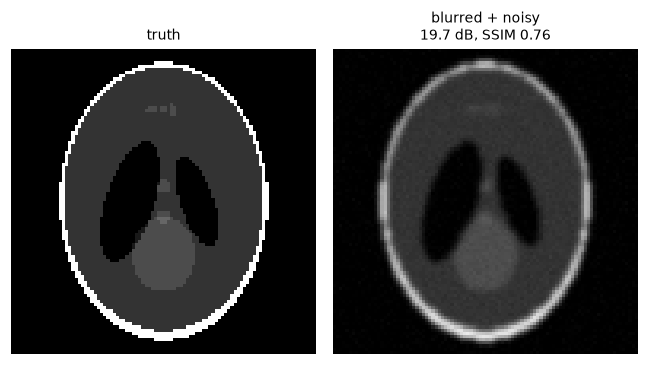

In [2]:
x_true = load_phantom("shepp-logan", size=96)
blur = GaussianBlur(sigma=1.0)
NOISE_SIGMA = 0.01
b = add_gaussian_noise(blur(x_true), NOISE_SIGMA, seed=1)
show({"truth": x_true, "blurred + noisy": np.clip(b, 0, 1)}, ref=x_true)

## 3. Check the operators

Every method here uses an operator and its adjoint. The dot-product test,
$\langle Ax, y\rangle = \langle x, A^*y\rangle$ for random $x, y$, catches
almost every implementation error. Run it on any operator you add. The
discrete gradient `TotalVariation.forward` maps an image to a stack of two
difference images, and `TotalVariation.adjoint` is its exact adjoint (minus
the divergence):

In [3]:
rng = np.random.default_rng(0)
u, v = rng.standard_normal(x_true.shape), rng.standard_normal(x_true.shape)
print(f"blur: <Au, v> / <u, A*v> = {np.vdot(blur(u), v) / np.vdot(u, blur.adjoint(v)):.12f}")

D = TotalVariation(weight=1.0)
p = rng.standard_normal((2, *x_true.shape))
print(f"gradient: <Du, p> / <u, D*p> = {np.vdot(D.forward(u), p) / np.vdot(u, D.adjoint(p)):.12f}")

blur: <Au, v> / <u, A*v> = 1.000000000000
gradient: <Du, p> / <u, D*p> = 1.000000000000


## 4. A smooth objective: adaptive gradient descent

Start with a smooth (differentiable) objective, Tikhonov regularization with
a gradient penalty:

$$f(x) = \tfrac12\|Ax - b\|^2 + \tfrac{\mu}{2}\|Dx\|^2 .$$

Plain gradient descent needs a step size of at most $1/L$, where $L$ bounds
the curvature; here $L \le 1 + 8\mu$. AdGD (Malitsky and Mishchenko, 2020)
estimates the local curvature from the last two iterates and gradients, so it
needs no step size and often takes longer steps than $1/L$.

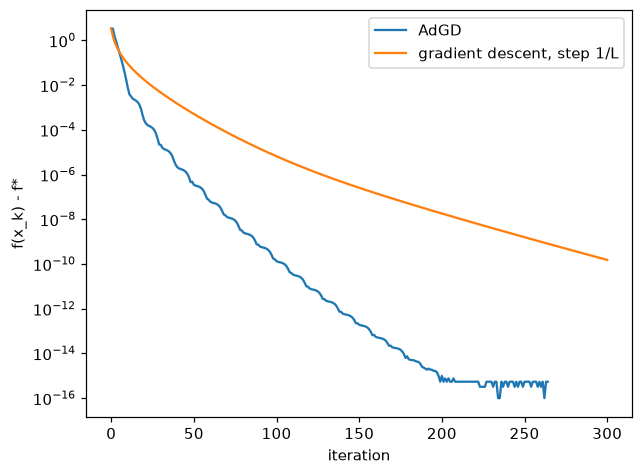

AdGD step sizes: median 1.76, max 17.62; 1/L = 0.93


In [4]:
MU = 0.01


def grad_f(x):
    return blur.adjoint(blur(x) - b) + MU * D.adjoint(D.forward(x))


def f(x):
    return 0.5 * np.sum((blur(x) - b) ** 2) + 0.5 * MU * np.sum(D.forward(x) ** 2)


res_adgd = adaptive_gradient_descent(grad_f, b.copy(), objective=f, max_iter=300, tol=1e-10)

L = 1.0 + 8.0 * MU
x = b.copy()
gd_history = [f(x)]
for _ in range(300):
    x = x - grad_f(x) / L
    gd_history.append(f(x))

f_star = min(min(res_adgd.objective_history), min(gd_history))
plot_convergence({"AdGD": np.array(res_adgd.objective_history) - f_star + 1e-16,
                  "gradient descent, step 1/L": np.array(gd_history) - f_star + 1e-16},
                 ylabel="f(x_k) - f*")
plt.show()

steps = np.array(res_adgd.step_size_history[1:])
print(f"AdGD step sizes: median {np.median(steps):.2f}, max {steps.max():.2f}; 1/L = {1 / L:.2f}")

AdGD reaches machine precision in about 200 iterations, without being told
$L$. Gradient descent with the safe step $1/L$ from the bound
$L \le 1 + 8\mu = 1.08$ is still near $10^{-10}$ after 300. AdGD's median
step, 1.76, is below the stability limit $2/L$ (the true $L$ is 0.999), so a
fixed step tuned close to $2/L$ would be about as fast. The point of AdGD is
that it needs neither $L$ nor tuning: use it whenever the objective is smooth
and you would otherwise have to guess a step size.

## 5. Adding constraints: quasi-Newton forward-backward splitting

Pixel values lie in $[0, 1]$. Adding that constraint makes the problem
non-smooth: minimize $f(x) + \iota_{[0,1]}(x)$. Forward-backward splitting
alternates a gradient step on $f$ with the proximal map of the constraint,
here a projection (`prox_box`). In the language of monotone inclusions it
solves $0 \in Az + Bz$ with $B = \nabla f$, which is $\beta$-cocoercive with
$\beta = 1/L$, and $A$ the normal cone of the box, whose resolvent is the
projection.

QN-FBS (Wang, Fadili and Ochs, 2022) replaces the fixed metric by a scaled
identity plus a rank-one quasi-Newton correction, which captures curvature at
almost no extra cost.

QN-FBS: 300 iterations


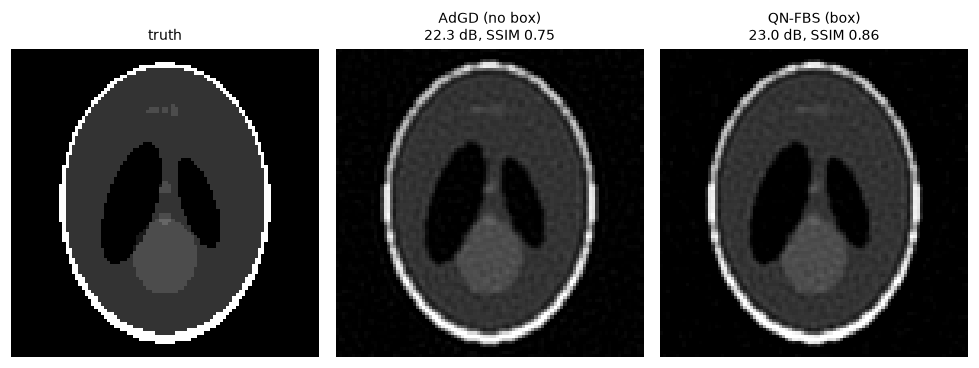

In [5]:
res_qn = inertial_quasi_newton_fbs(
    B=grad_f,
    resolvent_A=lambda z, theta: prox_box(z, 0.0, 1.0),
    z0=np.clip(b, 0, 1),
    beta=1.0 / L,
    objective=f,
    max_iter=300,
    tol=1e-10,
)
print(f"QN-FBS: {res_qn.n_iter} iterations")
show({"truth": x_true, "AdGD (no box)": np.clip(res_adgd.x, 0, 1), "QN-FBS (box)": res_qn.x},
     ref=x_true)

Both give a smooth, slightly blurry result: the quadratic penalty
$\|Dx\|^2$ punishes large jumps, so it cannot keep sharp edges.

## 6. Edge-preserving regularization: total variation with VarPDAL

Total variation replaces $\|Dx\|^2$ by $\|Dx\|_{2,1}$, the sum of the
gradient magnitudes, which allows sharp edges:

$$\min_x\ \tfrac12\|Ax - b\|^2 + w\,\|Dx\|_{2,1} + \iota_{[0,1]}(x).$$

It has no simple proximal map, so we use the saddle-point form
$\min_x \max_y \langle Dx, y\rangle + g(x) + h(x) - f^*(y)$ with
$g = \iota_{[0,1]}$, $h(x) = \tfrac12\|Ax-b\|^2$ (smooth, with
$L_h = \|A\|^2 \le 1$), and $f^*$ the indicator of the dual ball, whose
proximal map is `TotalVariation.prox_conj`. VarPDAL (Wang, Fadili and Ochs,
2024) handles the smooth term $h$ with a quasi-Newton metric and chooses its
step sizes by linesearch, so the only parameters are an initial dual step and
the ratio between primal and dual steps.

VarPDAL: 3000 iterations in 5.3 s


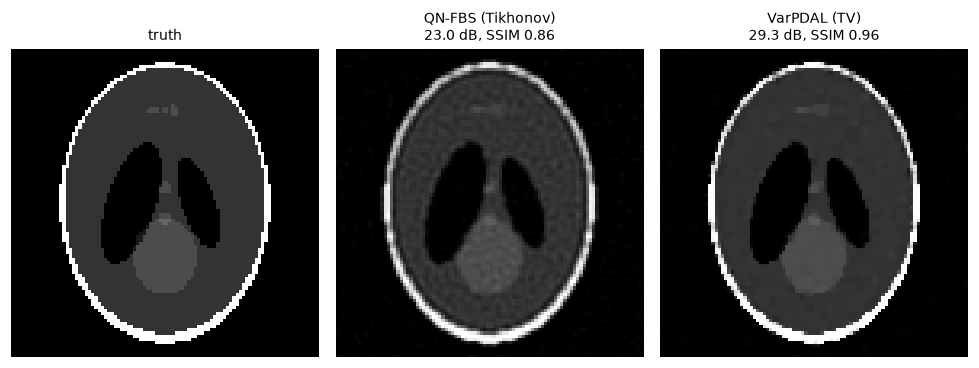

In [6]:
def restore_tv(weight, max_iter=3000):
    tv = TotalVariation(weight=weight)
    h = lambda x: 0.5 * np.sum((blur(x) - b) ** 2)
    return var_pdal(
        K=tv.forward, K_adjoint=tv.adjoint,
        prox_g=lambda z, tau: prox_box(z, 0.0, 1.0),
        prox_f_conj=tv.prox_conj,
        h=h, grad_h=lambda x: blur.adjoint(blur(x) - b),
        x1=np.clip(b, 0, 1), y0=np.zeros((2, *b.shape)),
        L_h=1.0, sigma0=0.1, beta=1.0,
        objective=lambda x: h(x) + tv(x),
        max_iter=max_iter, tol=1e-9,
    )


t0 = time.perf_counter()
res_tv = restore_tv(weight=1e-3)
print(f"VarPDAL: {res_tv.n_iter} iterations in {time.perf_counter() - t0:.1f} s")
show({"truth": x_true, "QN-FBS (Tikhonov)": res_qn.x, "VarPDAL (TV)": res_tv.x}, ref=x_true)

TV reaches 29.3 dB, against 23.0 dB for the smooth (Tikhonov-type) result of
QN-FBS, and keeps the edges sharp. It needs many more iterations than the
smooth problem: with a small weight the problem is close to plain deblurring,
which converges slowly. Here 3000 iterations take a few seconds; far fewer
stop short of the solution.

## 7. Choosing the TV weight from the data

The weight $w$ trades data fit against smoothness. With real data you cannot
compute PSNR, but you often know the noise level (from a flat region, or from
the sensor). The *discrepancy principle* picks the weight whose residual
$\|Ax_w - b\|$ matches the expected noise norm $\sigma\sqrt{N}$ for $N$
pixels:

In [7]:
noise_norm = NOISE_SIGMA * np.sqrt(b.size)
rows = []
for weight in (1e-4, 3e-4, 1e-3, 3e-3, 1e-2):
    xw = restore_tv(weight).x
    rows.append((weight, np.linalg.norm(blur(xw) - b), psnr(xw, x_true), ssim(xw, x_true)))
print(f"expected noise norm: {noise_norm:.3f}")
for weight, res, q, s_ in rows:
    print(f"w = {weight:.0e}: residual {res:.3f}, PSNR {q:.1f} dB, SSIM {s_:.3f}")
pick = min(rows, key=lambda r: abs(r[1] - noise_norm))
print(f"discrepancy principle picks w = {pick[0]:.0e} ({pick[2]:.1f} dB)")

expected noise norm: 0.960
w = 1e-04: residual 0.818, PSNR 28.0 dB, SSIM 0.780
w = 3e-04: residual 0.852, PSNR 30.9 dB, SSIM 0.907
w = 1e-03: residual 0.907, PSNR 29.3 dB, SSIM 0.963
w = 3e-03: residual 1.014, PSNR 25.7 dB, SSIM 0.958
w = 1e-02: residual 1.327, PSNR 22.5 dB, SSIM 0.923
discrepancy principle picks w = 1e-03 (29.3 dB)


The discrepancy principle picks $w = 10^{-3}$, which also gives the highest
SSIM in this sweep (0.963). The PSNR optimum is at a smaller weight
($3\times10^{-4}$, 30.9 dB), where the image keeps more noise. PSNR and SSIM
often disagree like this for TV, so judge the images as well as the numbers.

## 8. Your own images

Any 2-D grayscale array scaled to $[0, 1]$ works; there is no size limit
other than the blur kernel fitting inside the image. For a file on disk:

```python
import matplotlib.image as mpimg

img = mpimg.imread("my_image.png").astype(float)
if img.ndim == 3:                 # RGB(A) -> gray
    img = img[..., :3].mean(axis=2)
img = (img - img.min()) / (img.max() - img.min())
```

Then build `b` from it as in section 2, or use a blurred photograph as `b`
directly with a `GaussianBlur` that matches its blur. The built-in `circles`
phantom is used here:

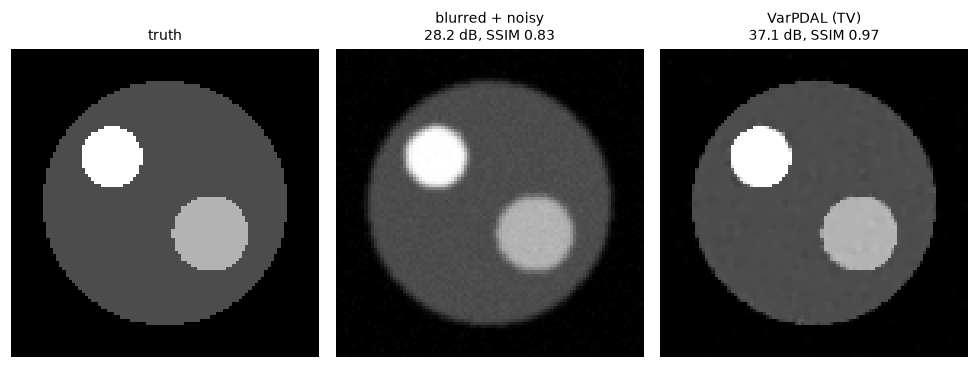

In [8]:
x_true = load_phantom("circles", size=96)
b = add_gaussian_noise(blur(x_true), NOISE_SIGMA, seed=2)
res = restore_tv(weight=1e-3)
show({"truth": x_true, "blurred + noisy": np.clip(b, 0, 1), "VarPDAL (TV)": res.x}, ref=x_true)

## Where to go next

- `THEORY.md` and `docs/imrestore-tech-note.pdf`: the algorithms, their
  assumptions and step-size rules, and the verification results.
- `examples/01_restoration_benchmark.ipynb`: the three methods side by side
  on denoising.
- `scripts/`: convergence demos on problems with known solutions.